# TOT_Skewness: 電子飛跡の再構成

TPC のエンコーダのヒット(ストリップ × クロック)から、反跳電子の**散乱点 `Pe`**、**進行方向 `Ve`**、**飛程 `Len`** を求めます。
SMILE_tool_box の `TOT_Skewness_Analysis` に相当します。

1. **TOT 補正**: 各ストリップの立ち上がりクロックを TOT(信号幅)で補正する
2. **3 次元同時計数**: 補正後のクロックでアノード(x)とカソード(y)を対応させ、3 次元の点群を作る
3. **座標変換**: x, y はストリップ × 0.8 mm、z は `(クロック − オフセット) × ドリフト速度`
4. **飛程**: 点群を囲む箱の対角線の長さ(`Track_Min`, `Track_Max` はその角)
5. **skewness**: 電荷分布の歪みから、飛跡の始点(散乱点)側を判定して `Pe` を決める
6. **方向**: 散乱点付近の TOT 補正後の点を、x-z 面と y-z 面でそれぞれ直線 $z = a\,(x - P_{e,x}) + P_{e,z}$ でフィットし、
   電子の進行方向 `Ve` を求める

### TOT 補正(TOT_Correction)

エンコーダは、ストリップごと・クロック(10 ns)ごとに「信号がしきい値を超えていたか」を 1 ビットで記録しています。
1 本のストリップで続けてヒットしているクロックの塊を 1 つのパルスとみなし、

- 立ち上がり `clk_min`(最初にしきい値を超えたクロック)、立ち下がり `clk_max`
- **TOT**(Time Over Threshold)= `clk_max − clk_min`。信号の大きさ(電荷)が大きいほど長い

とします(同じストリップでも 2 クロック以上空いたら別のパルス)。立ち上がりの時刻は信号が大きいほど早くなる(タイムウォーク)、
また電子の雲には時間方向の広がりがある、と考えられるので、パルスの代表時刻を TOT で補正します
(式の係数はデータから決めた経験的なもので、元の導出の資料は手元にありません):

$$t_{\rm corr} = {\rm clk_{min}} + a + b \times {\rm TOT}$$

| | $a$ [clock] | $b$ | 決めたデータ |
|---|---|---|---|
| アノード | 1.28996 | 0.432939 | 2019/07/01 の地上実験(Per02) |
| カソード | 0.69759 | 0.417947 | 同上 |

$b \approx 0.43$ なので、補正後の時刻はおおむねパルスの中ほどになります。これでストリップ 1 本・パルス 1 つにつき
1 点 `(ストリップ番号, t_corr)` が得られます(アノード: `str_a`, `corr_tot_a`、カソード: `str_c`, `corr_tot_c`)。

**3 次元同時計数**: アノードの点 $i$ とカソードの点 $j$ の補正後の時刻が $|t_{{\rm corr},i} - t_{{\rm corr},j}| \le 4$ クロックなら
同じ電子の雲とみなし、3 次元の点 (x = アノードのストリップ, y = カソードのストリップ, z = アノードの $t_{\rm corr}$) を作ります
(z は整数のクロックに切り捨ててから mm に変換)。これが散乱点を選ぶ点群 `caq` です。

### skewness による散乱点の決定

電子はガス中で止まる直前ほど単位長さあたりに多くのエネルギーを落とし(dE/dx が大きくなる)、多重散乱で曲がりやすくなります。
そのため**電荷は飛跡の終点側に偏り**、始点(= 散乱点)は電荷の少ない側になります。この偏りを skewness(歪度)で測ります。

1. **投影**: 全ヒット(TOT 補正前、同時計数前)を x 方向(アノードのストリップ)に投影し、ストリップごとのヒットクロック数
   $w(x)$ のヒストグラムを作る(1 ビン = 1 ストリップ。ヒットクロック数は TOT の合計で、そのストリップに落ちた電荷の目安)。y も同様。
2. **skewness**: 飛跡の両端の中点 $x_{\rm mid} = (x_{\min} + x_{\max})/2$ のまわりで
   $$S_x = \frac{\frac1N \sum w(x)\,(x - x_{\rm mid})^3}{\left[\frac1N \sum w(x)\,(x - x_{\rm mid})^2\right]^{3/2}}$$
   ($N$ はヒットのあったストリップの数)。重み付き平均ではなく**両端の中点**を基準にしているので、
   $S_x > 0$ は「電荷が +x 側の端に偏っている = +x 側が終点」を意味します。
   最後に実験から決めた補正を掛けています(2020/07/28):
   $S_x \to S_x - 0.0006029$、$S_y \to (S_y - 0.002347) \times 0.07857 / 0.08867$。
3. **散乱点**: $|S_x|$ と $|S_y|$ の大きい方の軸を使う(偏りがはっきりしている方が信頼できる)。x の場合:
   - $S_x \ge 0$(終点が +x 側)なら、3 次元の点群のうち **x が最小**の点を散乱点とする。$S_x < 0$ なら x が最大の点
   - x が同じ点が複数あれば、y で選ぶ($S_y \ge 0$ なら y が最小、負なら最大)
   - 選んだ点の (x, y, z) が `Pe`
   y の方が大きい場合は x と y を入れ替えて同じ手順です。
4. **方向**: `Pe` から x(または y)と z の両方で ±10 mm 以内にある TOT 補正後の点を、x-z 面・y-z 面でそれぞれ直線フィットする
   (以内の点が 1 つしかなければ、10 mm より外で一番近い点を 1 つ足す)。

### 出力の中身(添字 0 = x, 1 = y, 2 = z、単位 mm)

| 量 | 中身 |
|---|---|
| `Pe[0..2]` | 散乱点の x, y, z |
| `Ve[0..2]` | 電子の進行方向の x, y, z 成分。$s\,(1/a_x,\ 1/a_y,\ 1)$ = $s\,(dx/dz,\ dy/dz,\ 1)$ で、**長さ 1 ではない**。$s = \pm 1$ は散乱点より上(z が大きい側)と下のどちらにヒットが多いかで決める。フィットに失敗した軸があると、xy 面内の単位ベクトルと `Ve[2] = 0` になる |
| `Len` | 飛程。`Track_Min[0..2]` と `Track_Max[0..2]`(飛跡を囲む箱の角の x, y, z)の対角線の長さ |

再構成ツリー `single_hit` では `Pe_TRA[0..2]`、`Ve_TRA[0..2]`、`Len_TRA` に入ります(`[3..5]` は使わない枠)。

### ドリフト速度

ガスの状態でドリフト速度が時間変化するので、`drift_velocity.dat`(1 行目がクロックのオフセット、
以降が「経過時間 [h]、速度 [mm/clock]」の表)を、**イベントごとの時刻**(TPC 生データのヘッダにある
DAQ 開始からの経過時間カウンタ、生データツリーの `anode_time`)で引きます。

### パラメータ

| パラメータ | 値 | 意味 |
|---|---|---|
| `drift_velocity_file` | `.../20190701_Per02/drift_velocity.dat` | ドリフト速度の表 |
| `pitch_x_mm_per_strip`, `pitch_y_mm_per_strip` | 0.8 | ストリップピッチ [mm] |
| `flag_pixel_cut` | `False` | 不良ピクセルを除くか |
| `flag_save_cloud` | `False` | 点群をツリーに保存するか |

In [1]:
import sys, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials_caldata" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有)
CACHE.mkdir(exist_ok=True)

def vec(column):
    """RDataFrame.AsNumpy() の配列型の列 -> 2 次元の numpy 配列"""
    return np.stack([np.asarray(v) for v in column])

## 1. データの準備

データ(20190701 の較正データ **Per02**)の入手方法と置き場所は、
**[1_DataIO のノートブック](../../DataIO_example.ipynb) の「1. データの準備」**を見てください。
NAS を読める計算機では、ここでは何もする必要はありません。

下のセルで、設定ファイル `config/smile2p_20190701_Per02.json` が指すデータが見つかるかだけ確認します
(`MISSING` と出たら 1_DataIO の 1 節を見てください)。

In [2]:
CONFIG = "smile2p_20190701_Per02"
cfg = ec.load(CONFIG)
print("data_top:", ec.data_top())
for path in [cfg["parameters"]["ReadData"]["data_dir"], cfg["parameters"]["HA_Calc"]["parameter_dir"]]:
    print("OK     " if Path(path).is_dir() else "MISSING", path)

data_top: /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/calibration_data
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/calibration_data/sm2+_cal_rawdata/20190701_Per02
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/calibration_data/param/20190528


## 2. ドリフト速度の表

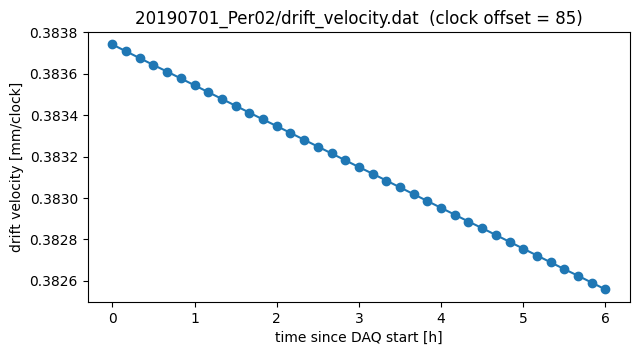

In [3]:
table = Path(cfg["parameters"]["TOT_Skewness"]["drift_velocity_file"])   # 設定ファイルに書かれた表
lines = table.read_text().split()
offset, vals = float(lines[0]), np.array(lines[1:], float).reshape(-1, 2)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(vals[:, 0], vals[:, 1], "o-")
ax.set_xlabel("time since DAQ start [h]"); ax.set_ylabel("drift velocity [mm/clock]")
ax.set_title(f"{table.parent.name}/{table.name}  (clock offset = {offset:g})")
plt.show()

## 3. 再構成ツリーを読む

全チェーンを先頭 50000 イベントで実行し、再構成ツリー `Reconstruct/single_hit` の `err_flag == 0` の行を読みます。

ターミナル(コマンドプロンプト)では、リポジトリの `run_script` ディレクトリで次を実行するのと同じです。

```bash
cd EricaNext_try/run_script
python3 run_chain.py smile2p_20190701_Per02 -o Per02_50000.root -n 50000
```

| 引数 | 意味 |
|---|---|
| `smile2p_20190701_Per02` | 設定ファイル `config/smile2p_20190701_Per02.json`(データの場所と各モジュールのパラメータ) |
| `-o Per02_50000.root` | 出力ファイル |
| `-n 50000` | 先頭 50000 イベントだけ処理する(省略すると全イベント、約 1 時間) |

下のセルは同じコマンドを Python から実行しています(`sys.executable` は今のカーネルの python3、
`RUN_CHAIN` は `run_chain.py` のパス、`CONFIG` は設定名)。出力は `tutorials_caldata/cache/` に置き、
既にあれば再実行しません(他のノートブックと共有)。

In [4]:
OUT = CACHE / "Per02_50000.root"
cmd = [sys.executable, str(RUN_CHAIN), CONFIG, "-o", str(OUT), "-n", "50000"]
print(" ".join(cmd))
if not OUT.exists():
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
    r.check_returncode()

/usr/bin/python3 /home/onoda/ANLNext/EricaNext_try/run_script/run_chain.py smile2p_20190701_Per02 -o /home/onoda/ANLNext/EricaNext_try/tutorials_caldata/cache/Per02_50000.root -n 50000


In [5]:
d = ROOT.RDataFrame("Reconstruct/single_hit", str(OUT)).Filter("err_flag == 0").AsNumpy(['err_flag', 'Len_TRA', 'skewness_x', 'skewness_y', 'Track_Min', 'Track_Max', 'Pe_TRA'])
ev = {k: (vec(v) if v.dtype == object else v) for k, v in d.items()}   # 配列型の列は 2 次元配列に
print("err_flag == 0:", len(ev["err_flag"]))

err_flag == 0: 26697


## 4. 飛跡の分布

飛程、skewness、飛跡の端点(`Track_Min`, `Track_Max`)の x-z, y-z 分布です。

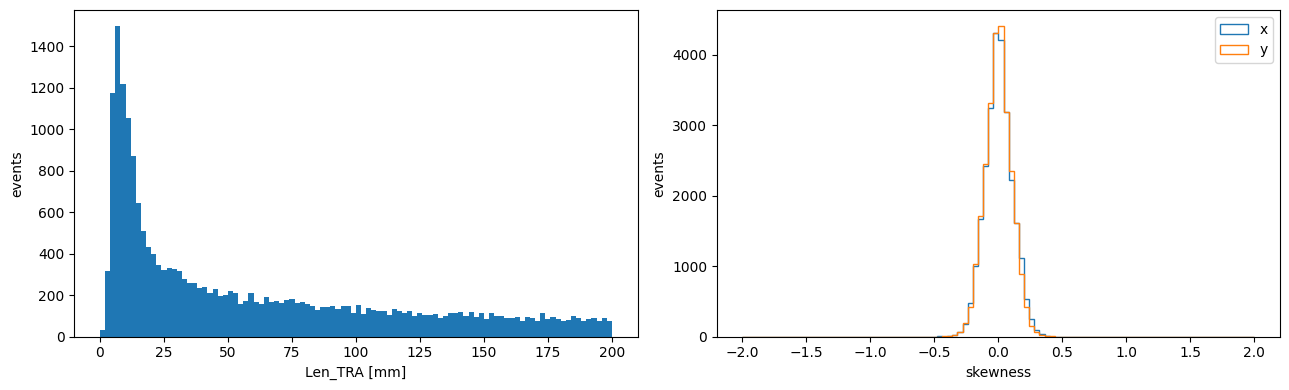

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(ev["Len_TRA"], bins=100, range=(0, 200)); ax[0].set_xlabel("Len_TRA [mm]"); ax[0].set_ylabel("events")
ax[1].hist(ev["skewness_x"], bins=100, range=(-2, 2), histtype="step", label="x")
ax[1].hist(ev["skewness_y"], bins=100, range=(-2, 2), histtype="step", label="y")
ax[1].set_xlabel("skewness"); ax[1].set_ylabel("events"); ax[1].legend()
fig.tight_layout(); plt.show()

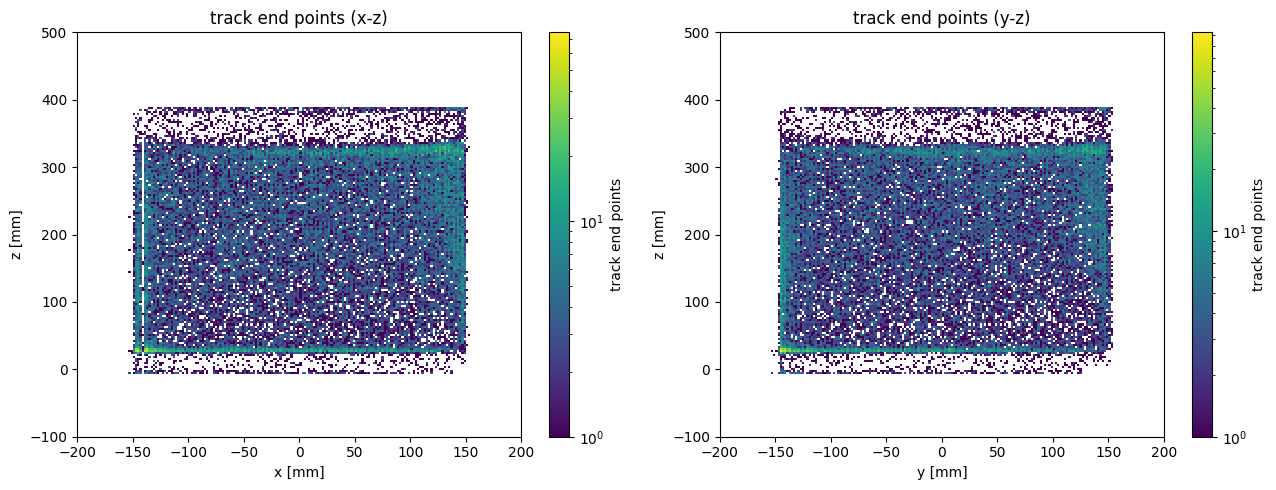

In [7]:
ends = np.concatenate([ev["Track_Min"], ev["Track_Max"]])
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, k, lab in [(ax[0], 0, "x"), (ax[1], 1, "y")]:
    h = a.hist2d(ends[:, k], ends[:, 2], bins=[200, 200], range=[[-200, 200], [-100, 500]], cmin=1, norm="log")
    fig.colorbar(h[3], ax=a, label="track end points")
    a.set_xlabel(f"{lab} [mm]"); a.set_ylabel("z [mm]"); a.set_title(f"track end points ({lab}-z)")
fig.tight_layout(); plt.show()